# Credit Scoring Model

## CodeAlpha Machine Learning Internship — Task 1

### Objective
To predict an individual's creditworthiness using past financial and loan-related data.

### Machine Learning Algorithms
1. Logistic Regression
2. Decision Tree
3. Random Forest

### Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC
- Confusion Matrix
- ROC Curve

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv(r"C:\Users\aruna\Downloads\archive (1)\credit_risk_dataset - Copy.csv")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 32581
Number of columns: 12


In [3]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [4]:
df.tail()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26
32580,66,42000,RENT,2.0,MEDICAL,B,6475,9.99,0,0.15,N,30


In [5]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB


In [6]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [7]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64


In [8]:
df["person_emp_length"] = df["person_emp_length"].fillna(
    df["person_emp_length"].median()
)

df["loan_int_rate"] = df["loan_int_rate"].fillna(
    df["loan_int_rate"].median()
)

In [9]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [10]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 165


In [11]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (32416, 12)


In [12]:
print("Loan Status Distribution:")
print(df["loan_status"].value_counts())

Loan Status Distribution:
loan_status
0    25327
1     7089
Name: count, dtype: int64


In [13]:
print("\nPercentage Distribution:")
print(df["loan_status"].value_counts(normalize=True) * 100)


Percentage Distribution:
loan_status
0    78.13117
1    21.86883
Name: proportion, dtype: float64


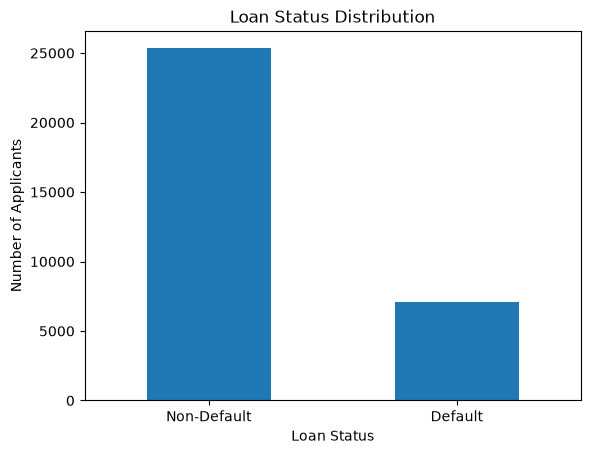

In [14]:
df["loan_status"].value_counts().plot(kind="bar")

plt.title("Loan Status Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")

plt.xticks(
    ticks=[0, 1],
    labels=["Non-Default", "Default"],
    rotation=0
)

plt.show()

In [15]:
print(df["person_home_ownership"].value_counts())

person_home_ownership
RENT        16378
MORTGAGE    13369
OWN          2563
OTHER         106
Name: count, dtype: int64


In [16]:
print(df["loan_intent"].value_counts())

loan_intent
EDUCATION            6411
MEDICAL              6042
VENTURE              5682
PERSONAL             5498
DEBTCONSOLIDATION    5189
HOMEIMPROVEMENT      3594
Name: count, dtype: int64


In [17]:
print(df["loan_grade"].value_counts())

loan_grade
A    10703
B    10387
C     6438
D     3620
E      963
F      241
G       64
Name: count, dtype: int64


In [18]:
print(df["cb_person_default_on_file"].value_counts())

cb_person_default_on_file
N    26686
Y     5730
Name: count, dtype: int64


In [19]:
df["loan_income_ratio"] = df["loan_amnt"] / df["person_income"]

In [20]:
df["income_per_emp_year"] = df["person_income"] / (
    df["person_emp_length"] + 1
)

In [21]:
df[[
    "person_income",
    "loan_amnt",
    "loan_income_ratio",
    "income_per_emp_year"
]].head()

,person_income,loan_amnt,loan_income_ratio,income_per_emp_year
0,59000,35000,0.593220,475.806452
1,9600,1000,0.104167,1600.000000
2,9600,5500,0.572917,4800.000000
3,65500,35000,0.534351,13100.000000
4,54400,35000,0.643382,6044.444444


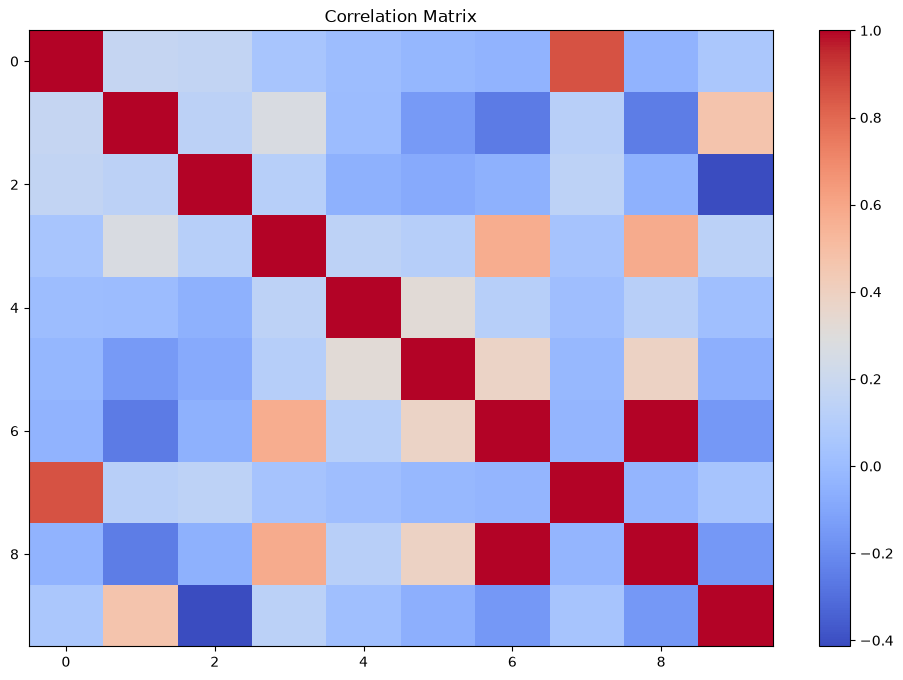

In [22]:
correlation = df.corr(numeric_only=True)

plt.figure(figsize=(12, 8))

plt.imshow(
    correlation,
    cmap="coolwarm",
    aspect="auto"
)

plt.colorbar()

plt.title("Correlation Matrix")

plt.show()

In [28]:
X = df.drop("loan_status", axis=1)
y = df["loan_status"]

In [29]:
X = pd.get_dummies(X, drop_first=True)

print("All features are now encoded.")
print(X.dtypes.value_counts())

All features are now encoded.
bool       15
float64     5
int64       4
Name: count, dtype: int64


In [30]:
print(X.select_dtypes(include="object").columns)

Index([], dtype='str')


In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (25932, 24)
Testing data: (6484, 24)


In [32]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

Feature scaling completed successfully!


In [33]:
logistic_model = LogisticRegression(
    max_iter=1000
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [34]:
y_pred_lr = logistic_model.predict(X_test_scaled)

y_prob_lr = logistic_model.predict_proba(
    X_test_scaled
)[:, 1]

print("Logistic Regression predictions generated.")

Logistic Regression predictions generated.


In [35]:
print("Logistic Regression Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=["Non-Default", "Default"]
    )
)

Logistic Regression Classification Report:

              precision    recall  f1-score   support

 Non-Default       0.89      0.96      0.92      5066
     Default       0.79      0.57      0.66      1418

    accuracy                           0.87      6484
   macro avg       0.84      0.76      0.79      6484
weighted avg       0.87      0.87      0.86      6484



In [36]:
lr_accuracy = accuracy_score(y_test, y_pred_lr)

lr_precision = precision_score(y_test, y_pred_lr)

lr_recall = recall_score(y_test, y_pred_lr)

lr_f1 = f1_score(y_test, y_pred_lr)

lr_roc_auc = roc_auc_score(y_test, y_prob_lr)

print("Logistic Regression Results")
print("--------------------------------")
print("Accuracy :", round(lr_accuracy, 4))
print("Precision:", round(lr_precision, 4))
print("Recall   :", round(lr_recall, 4))
print("F1-Score :", round(lr_f1, 4))
print("ROC-AUC  :", round(lr_roc_auc, 4))

Logistic Regression Results
--------------------------------
Accuracy : 0.8714
Precision: 0.7863
Recall   : 0.5656
F1-Score : 0.6579
ROC-AUC  : 0.8756


In [37]:
dt_model = DecisionTreeClassifier(
    max_depth=6,
    random_state=42
)

dt_model.fit(
    X_train,
    y_train
)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [38]:
y_pred_dt = dt_model.predict(X_test)

y_prob_dt = dt_model.predict_proba(
    X_test
)[:, 1]

print("Decision Tree predictions generated.")

Decision Tree predictions generated.


In [39]:
print("Decision Tree Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_dt,
        target_names=["Non-Default", "Default"]
    )
)

Decision Tree Classification Report:

              precision    recall  f1-score   support

 Non-Default       0.91      0.98      0.94      5066
     Default       0.92      0.64      0.76      1418

    accuracy                           0.91      6484
   macro avg       0.91      0.81      0.85      6484
weighted avg       0.91      0.91      0.90      6484



In [40]:
dt_accuracy = accuracy_score(y_test, y_pred_dt)

dt_precision = precision_score(y_test, y_pred_dt)

dt_recall = recall_score(y_test, y_pred_dt)

dt_f1 = f1_score(y_test, y_pred_dt)

dt_roc_auc = roc_auc_score(y_test, y_prob_dt)

print("Decision Tree Results")
print("--------------------------------")
print("Accuracy :", round(dt_accuracy, 4))
print("Precision:", round(dt_precision, 4))
print("Recall   :", round(dt_recall, 4))
print("F1-Score :", round(dt_f1, 4))
print("ROC-AUC  :", round(dt_roc_auc, 4))

Decision Tree Results
--------------------------------
Accuracy : 0.9101
Precision: 0.9213
Recall   : 0.6439
F1-Score : 0.758
ROC-AUC  : 0.8799


In [41]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [42]:
y_pred_rf = rf_model.predict(X_test)

y_prob_rf = rf_model.predict_proba(
    X_test
)[:, 1]

print("Random Forest predictions generated.")

Random Forest predictions generated.


In [43]:
print("Random Forest Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["Non-Default", "Default"]
    )
)

Random Forest Classification Report:

              precision    recall  f1-score   support

 Non-Default       0.93      0.99      0.96      5066
     Default       0.96      0.73      0.83      1418

    accuracy                           0.93      6484
   macro avg       0.94      0.86      0.89      6484
weighted avg       0.94      0.93      0.93      6484



In [44]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)

rf_precision = precision_score(y_test, y_pred_rf)

rf_recall = recall_score(y_test, y_pred_rf)

rf_f1 = f1_score(y_test, y_pred_rf)

rf_roc_auc = roc_auc_score(y_test, y_prob_rf)

print("Random Forest Results")
print("--------------------------------")
print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1-Score :", round(rf_f1, 4))
print("ROC-AUC  :", round(rf_roc_auc, 4))

Random Forest Results
--------------------------------
Accuracy : 0.9341
Precision: 0.9584
Recall   : 0.7306
F1-Score : 0.8291
ROC-AUC  : 0.9307


In [45]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        lr_accuracy,
        dt_accuracy,
        rf_accuracy
    ],

    "Precision": [
        lr_precision,
        dt_precision,
        rf_precision
    ],

    "Recall": [
        lr_recall,
        dt_recall,
        rf_recall
    ],

    "F1-Score": [
        lr_f1,
        dt_f1,
        rf_f1
    ],

    "ROC-AUC": [
        lr_roc_auc,
        dt_roc_auc,
        rf_roc_auc
    ]
})

results.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8714,0.7863,0.5656,0.6579,0.8756
1,Decision Tree,0.9101,0.9213,0.6439,0.7580,0.8799
2,Random Forest,0.9341,0.9584,0.7306,0.8291,0.9307


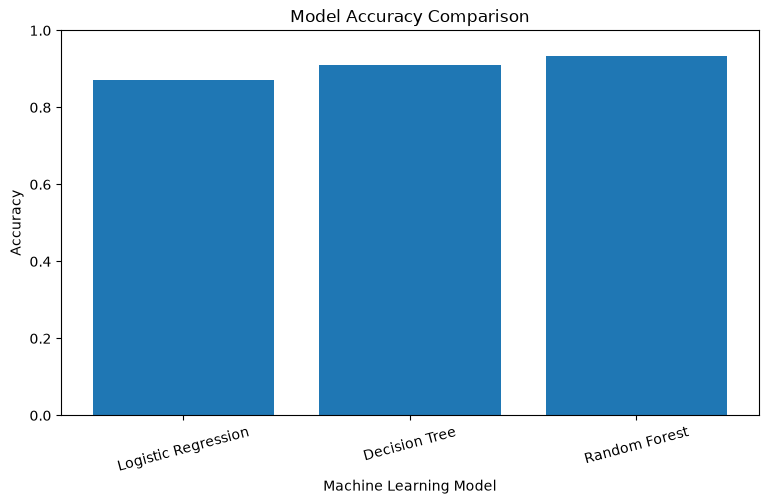

In [46]:
plt.figure(figsize=(9, 5))

plt.bar(
    results["Model"],
    results["Accuracy"]
)

plt.title("Model Accuracy Comparison")

plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")

plt.ylim(0, 1)

plt.xticks(rotation=15)

plt.show()

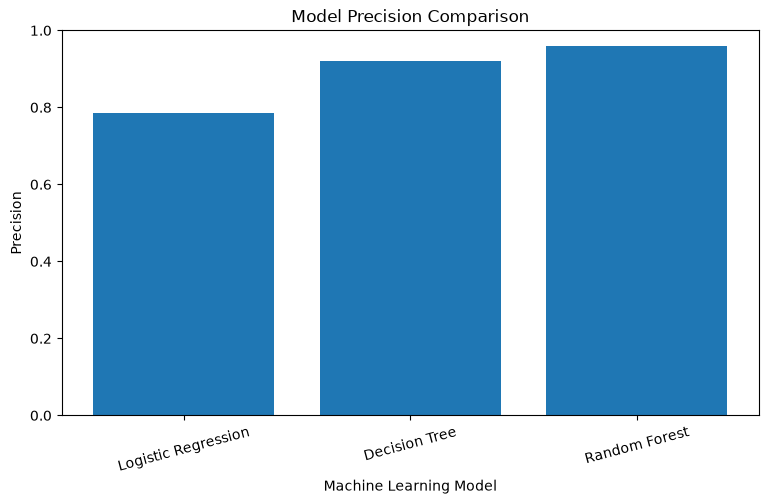

In [47]:
plt.figure(figsize=(9, 5))

plt.bar(
    results["Model"],
    results["Precision"]
)

plt.title("Model Precision Comparison")

plt.xlabel("Machine Learning Model")
plt.ylabel("Precision")

plt.ylim(0, 1)

plt.xticks(rotation=15)

plt.show()

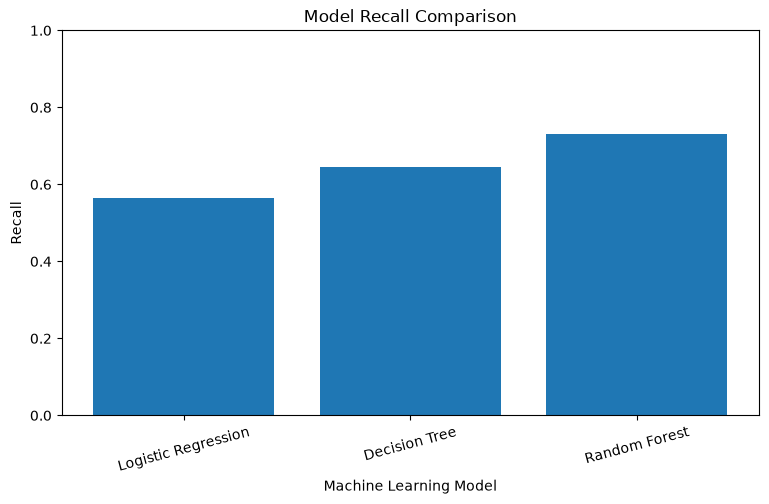

In [48]:
plt.figure(figsize=(9, 5))

plt.bar(
    results["Model"],
    results["Recall"]
)

plt.title("Model Recall Comparison")

plt.xlabel("Machine Learning Model")
plt.ylabel("Recall")

plt.ylim(0, 1)

plt.xticks(rotation=15)

plt.show()

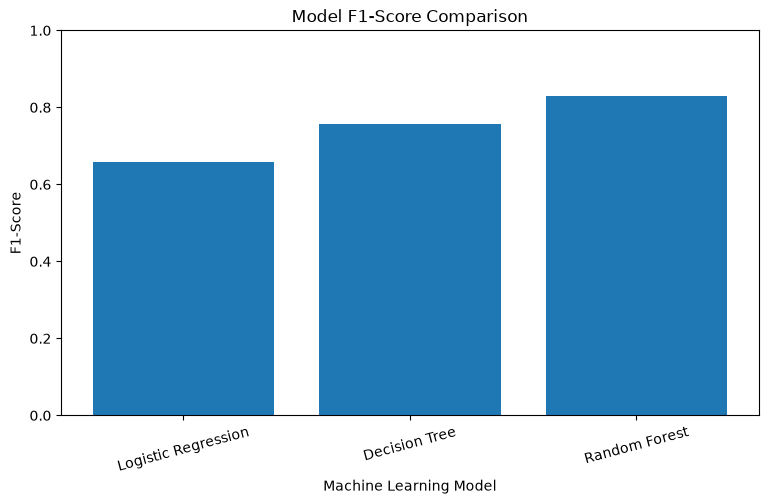

In [49]:
plt.figure(figsize=(9, 5))

plt.bar(
    results["Model"],
    results["F1-Score"]
)

plt.title("Model F1-Score Comparison")

plt.xlabel("Machine Learning Model")
plt.ylabel("F1-Score")

plt.ylim(0, 1)

plt.xticks(rotation=15)

plt.show()

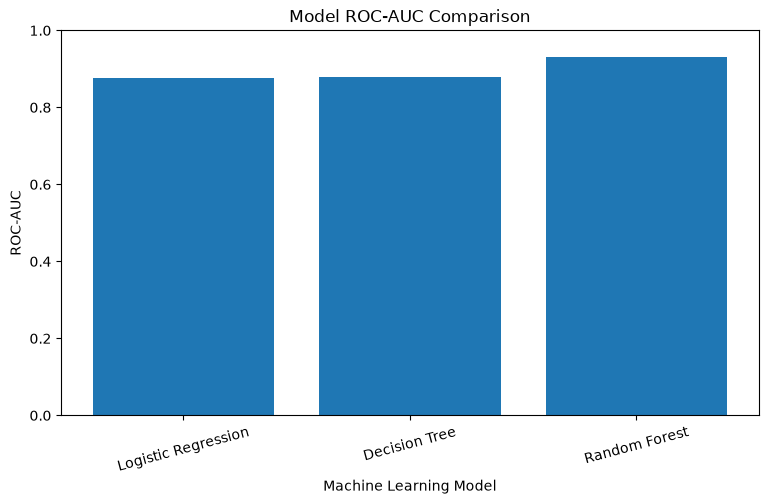

In [50]:
plt.figure(figsize=(9, 5))

plt.bar(
    results["Model"],
    results["ROC-AUC"]
)

plt.title("Model ROC-AUC Comparison")

plt.xlabel("Machine Learning Model")
plt.ylabel("ROC-AUC")

plt.ylim(0, 1)

plt.xticks(rotation=15)

plt.show()

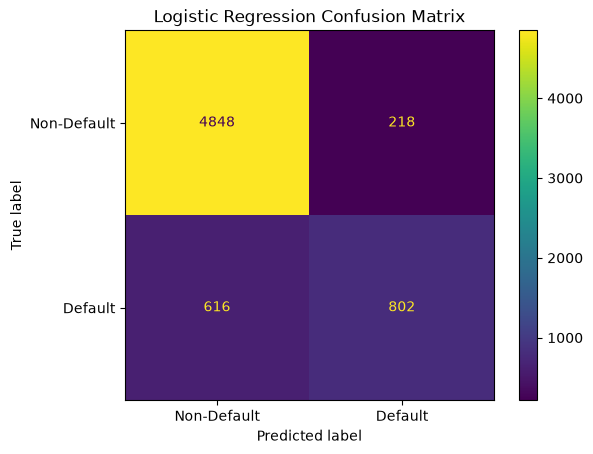

In [51]:
cm_lr = confusion_matrix(
    y_test,
    y_pred_lr
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=["Non-Default", "Default"]
)

disp.plot()

plt.title("Logistic Regression Confusion Matrix")

plt.show()

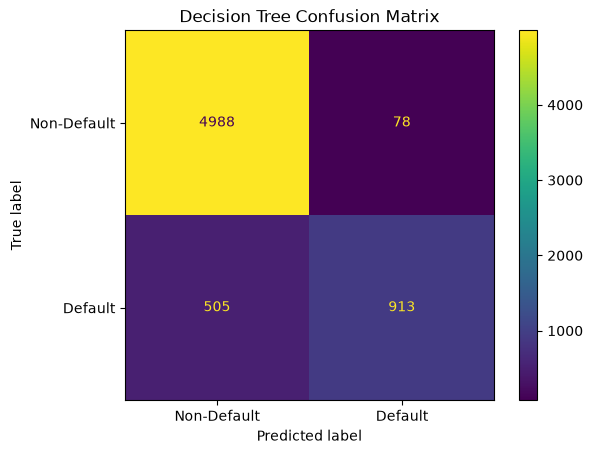

In [52]:
cm_dt = confusion_matrix(
    y_test,
    y_pred_dt
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=["Non-Default", "Default"]
)

disp.plot()

plt.title("Decision Tree Confusion Matrix")

plt.show()

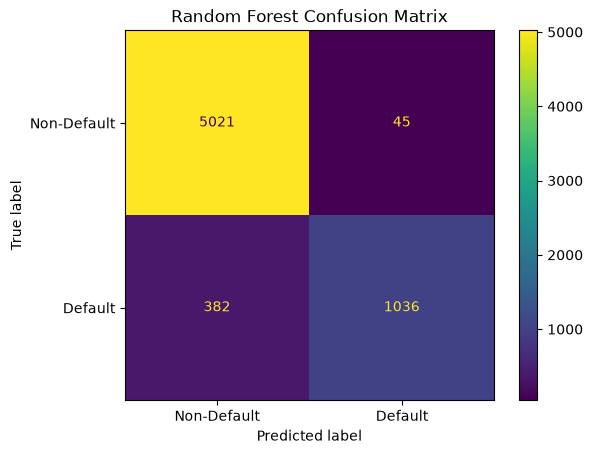

In [53]:
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Non-Default", "Default"]
)

disp.plot()

plt.title("Random Forest Confusion Matrix")

plt.show()

<Figure size 900x700 with 0 Axes>

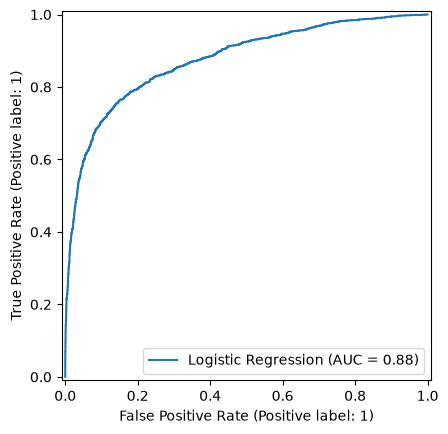

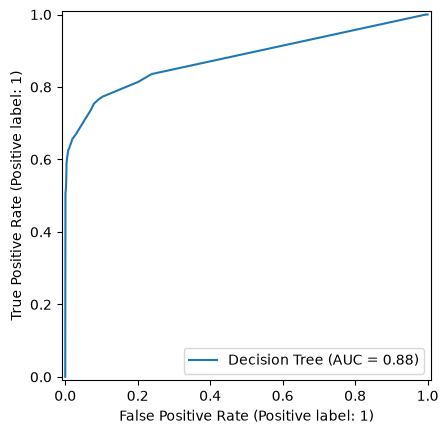

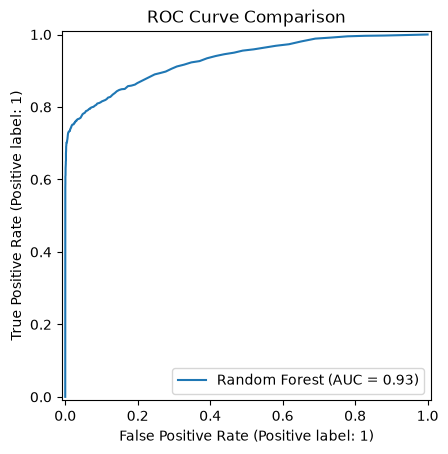

In [54]:
plt.figure(figsize=(9, 7))

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_lr,
    name="Logistic Regression"
)

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_dt,
    name="Decision Tree"
)

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_rf,
    name="Random Forest"
)

plt.title("ROC Curve Comparison")

plt.show()

In [55]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
7,loan_income_ratio,0.146281
5,loan_percent_income,0.129957
1,person_income,0.109430
4,loan_int_rate,0.098166
11,person_home_ownership_RENT,0.084283
19,loan_grade_D,0.063838
8,income_per_emp_year,0.061449
3,loan_amnt,0.056735
2,person_emp_length,0.043276
0,person_age,0.037859


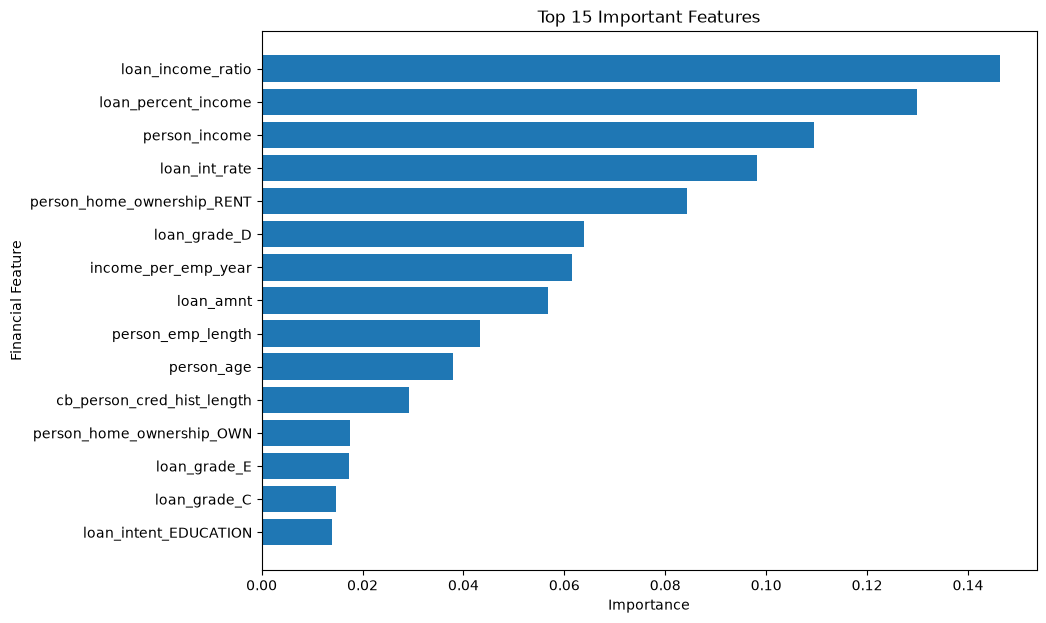

In [56]:
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")

plt.ylabel("Financial Feature")

plt.title("Top 15 Important Features")

plt.gca().invert_yaxis()

plt.show()

In [57]:
best_model = results.loc[
    results["ROC-AUC"].idxmax(),
    "Model"
]

best_auc = results["ROC-AUC"].max()

print("Model with highest ROC-AUC:", best_model)

print("ROC-AUC:", round(best_auc, 4))

Model with highest ROC-AUC: Random Forest
ROC-AUC: 0.9307


In [58]:
print("=" * 60)
print("FINAL MODEL RESULTS")
print("=" * 60)

display(results.round(4))

print("\nModel with highest ROC-AUC:")
print(best_model)

print("\nHighest ROC-AUC score:")
print(round(best_auc, 4))

FINAL MODEL RESULTS


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8714,0.7863,0.5656,0.6579,0.8756
1,Decision Tree,0.9101,0.9213,0.6439,0.7580,0.8799
2,Random Forest,0.9341,0.9584,0.7306,0.8291,0.9307



Model with highest ROC-AUC:
Random Forest

Highest ROC-AUC score:
0.9307


# Conclusion

In this project, a Credit Scoring Model was developed using machine learning techniques to predict loan status based on applicants' financial and credit-related information.

The dataset contains information such as age, income, employment length, home ownership, loan purpose, loan grade, loan amount, interest rate, loan-to-income ratio, previous default history, and credit history length.

The dataset was first explored through statistical analysis and visualization. Missing values were identified and handled using median imputation. Duplicate records were checked, and categorical variables were converted into numerical features using one-hot encoding.

Feature engineering was also performed by creating additional financial ratios from the available income, loan, and employment information.

Three classification algorithms were implemented:

1. Logistic Regression
2. Decision Tree
3. Random Forest

The models were evaluated using Accuracy, Precision, Recall, F1-Score, ROC-AUC, Confusion Matrix, and ROC Curve.

The performance comparison helps identify how different classification algorithms perform on the credit-risk dataset. The model with the highest ROC-AUC was identified automatically based on the experimental results.

This project demonstrates how machine learning can be applied to historical financial and credit-related data to support credit-risk assessment. The predictions should be considered as a machine-learning experiment and not as the sole basis for real-world lending decisions.